# DPSIM Three Machines Infinite Bus Benchmark System - 6 Buses and 3 Generators #

SP, DP and EMT Simulation

# Run C++ Examples #

In [1]:
import villas.dataprocessing.readtools as rt
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
import numpy as np
import dpsimpy
from pathlib import Path

# %matplotlib widget

/usr/local/lib/python3.13/site-packages/villas/dataprocessing/readtools.py:143: SyntaxWarning: invalid escape sequence '\['
  if re.search('\[D\] Stamping .+ into system matrix:', log_lines[line_pos]):
/usr/local/lib/python3.13/site-packages/villas/dataprocessing/readtools.py:145: SyntaxWarning: invalid escape sequence '\['
  elif re.search('\[I\] System matrix:', log_lines[line_pos]):
/usr/local/lib/python3.13/site-packages/villas/dataprocessing/readtools.py:147: SyntaxWarning: invalid escape sequence '\['
  elif re.search('\[D\] Stamping .+ into source vector:', log_lines[line_pos]):
/usr/local/lib/python3.13/site-packages/villas/dataprocessing/readtools.py:149: SyntaxWarning: invalid escape sequence '\['
  elif re.search('\[I\] Right side vector:', log_lines[line_pos]):
/usr/local/lib/python3.13/site-packages/villas/dataprocessing/readtools.py:151: SyntaxWarning: invalid escape sequence '\['
  elif re.search('\[I\] LU decomposition:', log_lines[line_pos]):
/usr/local/lib/python3.13/

# Imports and System Parameters #

In [2]:
# ======================= CONFIG =======================
USE_FAULT = True # False -> no-fault steady-state validation run (SP, DP and EMT)
USE_GOV = True # TurbineGovernorType1
USE_PSS = True # PSS1A
GEN_ORDER = 5 # 5 -> G1/G2 5th-order (GENSAE), G3 6b-order (GENROE) | 4 -> 4th-order
T_FAULT_ON = 1.0 # Three-phase fault inception at Bus 4 (s)
T_FAULT_OFF = 1.1 # Fault clearing time (100 ms / 6 cycles)
R_PU = 1e-6 # Minimum series resistance (pu on 100 MVA / 500 kV base)
C_LINE_TEST = 1e-8 # Line shunt capacitance [F] - same in PF, SP, DP and EMT
SW_OPEN = 1e9 # Fault switch open resistance  [ohm]
SW_CLOSED = 1e-2 # Fault switch closed resistance [ohm]

# --- Simulation parameters per domain ---
FINAL_TIME_SP = 15.0
DT_SP = 1e-3 # SP time step (1 ms)
FINAL_TIME_DP = 6.0
DT_DP = DT_SP # Same 1 ms step as SP and the reference DP/SP example.
FINAL_TIME_EMT = 6.0
DT_EMT = 25e-6 # EMT time step (25 us)

# --- DP diagnostic switch ---
DP_FAULT = USE_FAULT # False -> DP without fault: must stay flat at 60 Hz

# --- Plot windows ---
PLOT_TMAX = FINAL_TIME_EMT
ZOOM = (0.95, 1.30)   # fault window for the waveform zoom
# ======================================================

# -----------Power system-----------
F_NOM = 60.0
OMEGA = 2 * np.pi * F_NOM
V_HV = 500e3 # buses 4, 5, 6
V_LV = 18e3 # generator buses 1, 2, 3
S_BASE = 100e6
Z_BASE = V_HV**2 / S_BASE
TRAFO_RATING = 10_000e6
R_OHM = R_PU * Z_BASE

PSS = dict(Kp=0.0, Kv=0.0, Kw=5.0, T1=0.15, T2=0.03, T3=0.15, T4=0.03, Tw=10.0, Vs_max=0.1, Vs_min=-0.1)
GOV = (0.0, 1.0, 1.0, 0.5, 0.1, 0.05, 0.0, 1.2, 1.0)   # T3, T4, T5, Tc, Ts, R, Tmin, Tmax, OmRef

def xL(x_pu):
    return x_pu * Z_BASE / OMEGA

def vbase(b):
    return V_LV if b < 4 else V_HV

# -----------Generators (.dyr: GENSAE on Buses 1 and 2; GENROE on Bus 3)-----------
GEN = {
    1: dict(name="G1", S=1560e6, P=1404e6, Q=434.409e6, V=1.04, H=4.5, Ld=0.89, Lq=0.66, Ll=0.28,
            Ld_t=0.36, Lq_t=0.66, Td0_t=5.1, Tq0_t=1.0, Ld_s=0.29, Lq_s=0.29, Td0_s=0.06, Tq0_s=0.094, kind="GENSAE", Ka=100.0),
    2: dict(name="G2", S=1560e6, P=1404e6, Q=434.409e6, V=1.04, H=4.5, Ld=0.89, Lq=0.66, Ll=0.28,
            Ld_t=0.36, Lq_t=0.66, Td0_t=5.1, Tq0_t=1.0, Ld_s=0.29, Lq_s=0.29, Td0_s=0.06, Tq0_s=0.094, kind="GENSAE", Ka=100.0),
    3: dict(name="G3", S=890e6,  P=800e6,  Q=466.25e6,  V=1.02, H=3.859, Ld=1.72, Lq=1.679, Ll=0.266,
            Ld_t=0.488, Lq_t=0.8, Td0_t=5.3, Tq0_t=0.625, Ld_s=0.337, Lq_s=0.337, Td0_s=0.048, Tq0_s=0.066, kind="GENROE", Ka=150.0),
}

# -----------Loads (bus: (P, Q))-----------
LOADS   = {4: (1400e6, 100e6), 5: (2000e6, 100e6), 6: (10000e6, 2000e6)}

# -----------Transformers (from, to, X pu) and Transmission Lines (from, to, X pu)-----------
TRAFOS  = {"T14": (1, 4, 0.00641), "T24": (2, 4, 0.00641), "T35": (3, 5, 0.0112)}
LINES   = {"L45": (4, 5, 0.036), "L56": (5, 6, 0.120)}

# -----------Power-flow voltages used to scale the constant-Z loads-----------
V_PF_PU = {4: 1.016913, 5: 0.972777, 6: 1.0}
FAULT_BUS = 4

Path("logs").mkdir(exist_ok=True)


# Generator + Static Exciter (Controller Factory) #

In [3]:
def build_gen(p, domain):
    ns = {"sp": dpsimpy.sp.ph1, "dp": dpsimpy.dp.ph1, "emt": dpsimpy.emt.ph3}[domain]
    if GEN_ORDER == 4:
        g = ns.SynchronGenerator4OrderVBR(p["name"], dpsimpy.LogLevel.off)
        g.set_operational_parameters_per_unit(
            p["S"], V_LV, F_NOM, p["H"], p["Ld"], p["Lq"], p["Ll"],
            p["Ld_t"], p["Lq_t"], p["Td0_t"], p["Tq0_t"]
        )
    else:
        cls = ns.SynchronGenerator5OrderVBR if p["kind"] == "GENSAE" else ns.SynchronGenerator6bOrderVBR
        g = cls(p["name"], dpsimpy.LogLevel.off)
        g.set_operational_parameters_per_unit(
            p["S"], V_LV, F_NOM, p["H"], p["Ld"], p["Lq"], p["Ll"],
            p["Ld_t"], p["Lq_t"], p["Td0_t"], p["Tq0_t"],
            p["Ld_s"], p["Lq_s"], p["Td0_s"], p["Tq0_s"], 0.0
        )

    # Static Exciter (SCRX)
    ep = dpsimpy.signal.ExciterStaticParameters()
    ep.Ta = 1.0; ep.Tb = 1.0; ep.Ka = p["Ka"]; ep.Te = 0.05
    ep.MinEfd = -5.0; ep.MaxEfd = 5.0; ep.Tr = 1e-3; ep.Kbc = 0.0
    e = dpsimpy.signal.ExciterStatic(f"{p['name']}_Exc", dpsimpy.LogLevel.off)
    e.set_parameters(ep)
    g.add_exciter(e)

    # Power System Stabilizer (PSS1A)
    if USE_PSS:
        pp = dpsimpy.signal.PSS1AParameters()
        for k, v in PSS.items():
            setattr(pp, k, v)
        ps = dpsimpy.signal.PSS1A(f"{p['name']}_PSS", dpsimpy.LogLevel.off)
        ps.set_parameters(pp)
        g.add_pss(ps)

    # Turbine Governor Type 1
    if USE_GOV:
        gv = dpsimpy.signal.TurbineGovernorType1(f"{p['name']}_Gov", dpsimpy.LogLevel.off)
        gv.set_parameters(*GOV)
        g.add_governor(gv)

    return g

# PowerFlow for Initialization # 
SP + NRP. One PowerFlow initializes the SP, DP and EMT simulations.

In [4]:
sim_name_pf = "3MIB_PF"
dpsimpy.Logger.set_log_dir("logs/" + sim_name_pf)

nodes_pf = {i: dpsimpy.sp.SimNode(f"n{i}", dpsimpy.PhaseType.Single) for i in range(1, 7)}
comps_pf, gens_pf = [], {}

# 1. Local Synchronous Generators (PV Buses at 18 kV)
for b, p in GEN.items():
    g = dpsimpy.sp.ph1.SynchronGenerator(p["name"], dpsimpy.LogLevel.off)
    g.set_parameters(p["S"], V_LV, p["P"], V_LV * p["V"], dpsimpy.PowerflowBusType.PV, p["Q"], 9.9e9, -9.9e9)
    g.set_base_voltage(V_LV)
    g.connect([nodes_pf[b]])
    comps_pf.append(g)
    gens_pf[b] = g

# 2. Constant-PQ Loads (Buses 4, 5, and 6)
for b, (P, Q) in LOADS.items():
    l = dpsimpy.sp.ph1.Load(f"Load{b}", dpsimpy.LogLevel.off)
    l.set_parameters(P, Q, vbase(b))
    l.connect([nodes_pf[b]])
    comps_pf.append(l)

# 3. Infinite Bus / Slack Source at Bus 6 (VD Bus at 500 kV)
s_pf = dpsimpy.sp.ph1.NetworkInjection("Slack", dpsimpy.LogLevel.off)
s_pf.set_parameters(V_HV)
s_pf.set_base_voltage(V_HV)
s_pf.modify_power_flow_bus_type(dpsimpy.PowerflowBusType.VD)
s_pf.connect([nodes_pf[6]])
comps_pf.append(s_pf)

# 4. Step-Up Transformers (18 kV -> 500 kV)
for n, (a, b, x) in TRAFOS.items():
    t = dpsimpy.sp.ph1.Transformer(n, dpsimpy.LogLevel.off)
    t.set_parameters(V_LV, V_HV, TRAFO_RATING, V_LV / V_HV, 0.0, R_OHM, xL(x))
    t.set_base_voltage(V_HV)
    t.connect([nodes_pf[a], nodes_pf[b]])
    comps_pf.append(t)

# 5. Transmission Lines (500 kV)
for n, (a, b, x) in LINES.items():
    l = dpsimpy.sp.ph1.PiLine(n, dpsimpy.LogLevel.off)
    l.set_parameters(R_OHM, xL(x), C_LINE_TEST, 0.0)
    l.set_base_voltage(V_HV)
    l.connect([nodes_pf[a], nodes_pf[b]])
    comps_pf.append(l)

# 6. Fault branch present but open during power-flow initialization (same pattern as reference)
fault_pf = dpsimpy.sp.ph1.Switch("Br_fault", dpsimpy.LogLevel.off)
fault_pf.set_parameters(SW_OPEN, SW_CLOSED)
fault_pf.open()
fault_pf.connect([dpsimpy.sp.SimNode.gnd, nodes_pf[FAULT_BUS]])
comps_pf.append(fault_pf)

system_pf = dpsimpy.SystemTopology(F_NOM, list(nodes_pf.values()), comps_pf)

# Logging
logger_pf = dpsimpy.Logger(sim_name_pf)
for b, n in nodes_pf.items():
    logger_pf.log_attribute(f"v_bus{b}", "v", n)

# Simulation
sim_pf = dpsimpy.Simulation(sim_name_pf, dpsimpy.LogLevel.off)
sim_pf.set_system(system_pf)
sim_pf.set_time_step(1.0)
sim_pf.set_final_time(2.0)
sim_pf.set_domain(dpsimpy.Domain.SP)
sim_pf.set_solver(dpsimpy.Solver.NRP)
sim_pf.set_solver_component_behaviour(dpsimpy.SolverBehaviour.Initialization)
sim_pf.do_init_from_nodes_and_terminals(False)
sim_pf.add_logger(logger_pf)
sim_pf.run()

# Values from the 3IMB Texas File
res_pf = rt.read_timeseries_dpsim(f"logs/{sim_name_pf}/{sim_name_pf}.csv")
ref_pf = {1: (1.04, 50.572), 2: (1.04, 50.572), 3: (1.02, 20.048), 4: (1.016913, 45.691), 5: (0.972777, 14.867), 6: (1.0, 0.0)}
rows = []
for b in range(1, 7):
    v = res_pf[f"v_bus{b}"].values[-1]
    rows.append({
        "Bus": b,
        "V_solved_pu": abs(v) / vbase(b),
        "V_target_pu": ref_pf[b][0],
        "Angle_solved_deg": np.degrees(np.angle(v)),
        "Angle_target_deg": ref_pf[b][1],
    })
display(pd.DataFrame(rows).set_index("Bus"))


column number: 6
results length: 3
real column names: []
complex column names: ['v_bus1', 'v_bus2', 'v_bus3', 'v_bus4', 'v_bus5', 'v_bus6']


[12:57:46.790252 L45 warning] Zero value for Conductance, setting default value of G=1e-06 [S]
[12:57:46.790528 L56 warning] Zero value for Conductance, setting default value of G=1e-06 [S]
[12:57:46.794918 3MIB_PF_PF_Solver warning] Unable to get base voltage at n4


,V_solved_pu,V_target_pu,Angle_solved_deg,Angle_target_deg
Bus,,,,
1,1.040000,1.040000,48.044260,50.572
2,1.040000,1.040000,48.044260,50.572
3,1.020000,1.020000,17.816404,20.048
4,1.013905,1.016913,43.159252,45.691
5,0.969552,0.972777,12.636843,14.867
6,1.000000,1.000000,0.000000,0.000


# DP Simulation #
Dynamic Simulation

In [5]:
sim_name_dp = "3MIB_DP"
dpsimpy.Logger.set_log_dir("logs/" + sim_name_dp)

# Components
nodes_dp = {i: dpsimpy.dp.SimNode(f"n{i}", dpsimpy.PhaseType.Single) for i in range(1, 7)}
comps_dp, gs_dp, branches_dp, loads_dp = [], {}, {}, {}

# 1. Synchronous Generators + Controls (VBR 5th/6b-order as defined in build_gen)
for b, p in GEN.items():
    g = build_gen(p, "dp")
    g.connect([nodes_dp[b]])
    comps_dp.append(g)
    gs_dp[b] = g

# 2. Constant-Z Loads
for b, (P, Q) in LOADS.items():
    l = dpsimpy.dp.ph1.RXLoad(f"Load{b}", dpsimpy.LogLevel.off)
    l.set_parameters(P, Q, vbase(b) * (V_PF_PU[b] if b >= 4 else 1.0))
    l.connect([nodes_dp[b]])
    comps_dp.append(l)
    loads_dp[b] = l

# 3. Infinite Bus at Bus 6. DP source frequency is an offset from the carrier;
#    f_src=0 means it remains at the nominal 60 Hz carrier.
s_dp = dpsimpy.dp.ph1.NetworkInjection("Slack", dpsimpy.LogLevel.off)
s_dp.set_parameters(complex(V_HV, 0.0), 0.0)
s_dp.connect([nodes_dp[6]])
comps_dp.append(s_dp)

# 4. Step-Up Transformers & Transmission Lines
for n, (a, b, x) in TRAFOS.items():
    t = dpsimpy.dp.ph1.Transformer(n, dpsimpy.LogLevel.off)
    t.set_parameters(V_LV, V_HV, TRAFO_RATING, V_LV / V_HV, 0.0, R_OHM, xL(x))
    t.connect([nodes_dp[a], nodes_dp[b]])
    comps_dp.append(t)
    branches_dp[n] = t

for n, (a, b, x) in LINES.items():
    l = dpsimpy.dp.ph1.PiLine(n, dpsimpy.LogLevel.off)
    l.set_parameters(R_OHM, xL(x), C_LINE_TEST, 0.0)
    l.connect([nodes_dp[a], nodes_dp[b]])
    comps_dp.append(l)
    branches_dp[n] = l

# 5. Fault switch
fault_dp = dpsimpy.dp.ph1.varResSwitch("Br_fault", dpsimpy.LogLevel.off)
fault_dp.set_parameters(SW_OPEN, SW_CLOSED)
fault_dp.set_init_parameters(DT_DP)  # Must match the DP simulation time step?
fault_dp.open()
fault_dp.connect([dpsimpy.dp.SimNode.gnd, nodes_dp[FAULT_BUS]])
comps_dp.append(fault_dp)

system_dp = dpsimpy.SystemTopology(F_NOM, list(nodes_dp.values()), comps_dp)
system_dp.init_with_powerflow(system_pf, dpsimpy.Domain.DP)
# Re-apply the infinite-bus reference after power-flow initialization.
s_dp.set_parameters(complex(V_HV, 0.0), 0.0)

# Initialize generator internal states from converged Power Flow
for b, g in gs_dp.items():
    sp_ = gens_pf[b].get_apparent_power()
    g.set_initial_values(
        init_complex_electrical_power=sp_,
        init_mechanical_power=sp_.real,
        init_complex_terminal_voltage=nodes_dp[b].initial_single_voltage(),
    )

# Logging
logger_dp = dpsimpy.Logger(sim_name_dp)
for b, n in nodes_dp.items():
    logger_dp.log_attribute(f"v_bus{b}", "v", n)
for b, g in gs_dp.items():
    logger_dp.log_attribute(f"v_gen{b}", "v_intf", g)
    logger_dp.log_attribute(f"i_gen{b}", "i_intf", g)
    for k, a in (("wr", "w_r"), ("Te", "Te"), ("Tm", "Tm"), ("Ef", "Ef"), ("dl", "delta")):
        logger_dp.log_attribute(f"{k}{b}", a, g)
for name, comp in branches_dp.items():
    logger_dp.log_attribute(f"v_{name}", "v_intf", comp)
    logger_dp.log_attribute(f"i_{name}", "i_intf", comp)
for b, comp in loads_dp.items():
    logger_dp.log_attribute(f"v_load{b}", "v_intf", comp)
    logger_dp.log_attribute(f"i_load{b}", "i_intf", comp)
logger_dp.log_attribute("v_slack", "v_intf", s_dp)
logger_dp.log_attribute("i_slack", "i_intf", s_dp)
logger_dp.log_attribute("i_fault", "i_intf", fault_dp)

# Simulation
sim_dp = dpsimpy.Simulation(sim_name_dp, dpsimpy.LogLevel.off)
sim_dp.set_system(system_dp)
sim_dp.set_time_step(DT_DP)
sim_dp.set_final_time(FINAL_TIME_DP)
sim_dp.set_domain(dpsimpy.Domain.DP)
sim_dp.add_logger(logger_dp)
sim_dp.do_system_matrix_recomputation(True)

# Events
if DP_FAULT:
    sim_dp.add_event(dpsimpy.event.SwitchEvent(T_FAULT_ON, fault_dp, True))
    sim_dp.add_event(dpsimpy.event.SwitchEvent(T_FAULT_OFF, fault_dp, False))

sim_dp.run()
print(f"DP simulation finished (dt = {DT_DP*1e3:.3f} ms, fault = {DP_FAULT}, C_line = {C_LINE_TEST:g} F).")


DP simulation finished (dt = 1.000 ms, fault = True, C_line = 1e-08 F).


[12:57:49.149670 MnaSolverFactory info] creating KLUAdapter solver implementation


1.000000e+00: Handle event time
1.100000e+00: Handle event time


# SP Simulation #
Dynamic Simulation 

In [6]:
sim_name_sp = "3MIB_SP"
dpsimpy.Logger.set_log_dir("logs/" + sim_name_sp)

# Components
nodes_sp = {i: dpsimpy.sp.SimNode(f"n{i}", dpsimpy.PhaseType.Single) for i in range(1, 7)}
comps_sp, gs_sp, branches_sp, loads_sp = [], {}, {}, {}

# 1. Synchronous Generators + Controls
for b, p in GEN.items():
    g = build_gen(p, "sp")
    g.connect([nodes_sp[b]])
    comps_sp.append(g)
    gs_sp[b] = g

# 2. Constant-Z Loads scaled to PF voltage
for b, (P, Q) in LOADS.items():
    l = dpsimpy.sp.ph1.Load(f"Load{b}", dpsimpy.LogLevel.off)
    l.set_parameters(P, Q, vbase(b) * (V_PF_PU[b] if b >= 4 else 1.0))
    l.connect([nodes_sp[b]])
    comps_sp.append(l)
    loads_sp[b] = l

# 3. Infinite Bus at Bus 6
s_sp = dpsimpy.sp.ph1.NetworkInjection("Slack", dpsimpy.LogLevel.off)
s_sp.set_parameters(complex(V_HV, 0.0))
s_sp.set_base_voltage(V_HV)
s_sp.modify_power_flow_bus_type(dpsimpy.PowerflowBusType.VD)
s_sp.connect([nodes_sp[6]])
comps_sp.append(s_sp)

# 4. Step-Up Transformers & Transmission Lines
for n, (a, b, x) in TRAFOS.items():
    t = dpsimpy.sp.ph1.Transformer(n, dpsimpy.LogLevel.off)
    t.set_parameters(V_LV, V_HV, TRAFO_RATING, V_LV / V_HV, 0.0, R_OHM, xL(x))
    t.set_base_voltage(V_HV)
    t.connect([nodes_sp[a], nodes_sp[b]])
    comps_sp.append(t)
    branches_sp[n] = t

for n, (a, b, x) in LINES.items():
    l = dpsimpy.sp.ph1.PiLine(n, dpsimpy.LogLevel.off)
    l.set_parameters(R_OHM, xL(x), C_LINE_TEST, 0.0)
    l.set_base_voltage(V_HV)
    l.connect([nodes_sp[a], nodes_sp[b]])
    comps_sp.append(l)
    branches_sp[n] = l

# 5. Fault switch: use the same varResSwitch model as the reference DP/SP notebook.
# The terminal order [ground, bus] should in SP, DP and EMT or should be different from each other?
fault_sp = dpsimpy.sp.ph1.varResSwitch("Br_fault", dpsimpy.LogLevel.off)
fault_sp.set_parameters(SW_OPEN, SW_CLOSED)
fault_sp.set_init_parameters(DT_SP)
fault_sp.open()
fault_sp.connect([dpsimpy.sp.SimNode.gnd, nodes_sp[FAULT_BUS]])
comps_sp.append(fault_sp)

system_sp = dpsimpy.SystemTopology(F_NOM, list(nodes_sp.values()), comps_sp)
system_sp.init_with_powerflow(system_pf, dpsimpy.Domain.SP)
s_sp.set_parameters(complex(V_HV, 0.0))  # Keep the infinite-bus reference fixed after initialization

# Initialize generator internal states from converged Power Flow
for b, g in gs_sp.items():
    sp_ = gens_pf[b].get_apparent_power()
    g.set_initial_values(
        init_complex_electrical_power=sp_,
        init_mechanical_power=sp_.real,
        init_complex_terminal_voltage=nodes_sp[b].initial_single_voltage(),
    )

# Logging
logger_sp = dpsimpy.Logger(sim_name_sp)
for b, n in nodes_sp.items():
    logger_sp.log_attribute(f"v_bus{b}", "v", n)
for b, g in gs_sp.items():
    logger_sp.log_attribute(f"v_gen{b}", "v_intf", g)
    logger_sp.log_attribute(f"i_gen{b}", "i_intf", g)
    for k, a in (("wr", "w_r"), ("Te", "Te"), ("Tm", "Tm"), ("Ef", "Ef"), ("dl", "delta")):
        logger_sp.log_attribute(f"{k}{b}", a, g)
for name, comp in branches_sp.items():
    logger_sp.log_attribute(f"v_{name}", "v_intf", comp)
    logger_sp.log_attribute(f"i_{name}", "i_intf", comp)
for b, comp in loads_sp.items():
    logger_sp.log_attribute(f"v_load{b}", "v_intf", comp)
    logger_sp.log_attribute(f"i_load{b}", "i_intf", comp)
logger_sp.log_attribute("v_slack", "v_intf", s_sp)
logger_sp.log_attribute("i_slack", "i_intf", s_sp)
logger_sp.log_attribute("i_fault", "i_intf", fault_sp)

# Simulation
sim_sp = dpsimpy.Simulation(sim_name_sp, dpsimpy.LogLevel.off)
sim_sp.set_system(system_sp)
sim_sp.set_time_step(DT_SP)
sim_sp.set_final_time(FINAL_TIME_SP)
sim_sp.set_domain(dpsimpy.Domain.SP)
sim_sp.add_logger(logger_sp)
sim_sp.do_system_matrix_recomputation(True)

# Events
if USE_FAULT:
    sim_sp.add_event(dpsimpy.event.SwitchEvent(T_FAULT_ON, fault_sp, True))
    sim_sp.add_event(dpsimpy.event.SwitchEvent(T_FAULT_OFF, fault_sp, False))

sim_sp.run()
print("SP simulation finished.")


SP simulation finished.


[12:57:55.349134 L45 warning] Zero value for Conductance, setting default value of G=1e-06 [S]
[12:57:55.349418 L56 warning] Zero value for Conductance, setting default value of G=1e-06 [S]
[12:57:55.356090 MnaSolverFactory info] creating KLUAdapter solver implementation


1.000000e+00: Handle event time
1.100000e+00: Handle event time


# EMT Simulation #
Dynamic Simulation

In [7]:
sim_name_emt = "3MIB_EMT"
dpsimpy.Logger.set_log_dir("logs/" + sim_name_emt)
to3 = lambda v: dpsimpy.Math.single_phase_parameter_to_three_phase(float(v))

# Components
nodes_emt = {i: dpsimpy.emt.SimNode(f"n{i}", dpsimpy.PhaseType.ABC) for i in range(1, 7)}
comps_emt, gs_emt = [], {}

# 1. Three-Phase Synchronous Generators + Controls
for b, p in GEN.items():
    g = build_gen(p, "emt")
    g.connect([nodes_emt[b]])
    comps_emt.append(g)
    gs_emt[b] = g

# 2. Three-Phase Constant-Z Loads scaled to PF voltage
for b, (P, Q) in LOADS.items():
    l = dpsimpy.emt.ph3.RXLoad(f"Load{b}", dpsimpy.LogLevel.off)
    l.set_parameters(
        dpsimpy.Math.single_phase_power_to_three_phase(P),
        dpsimpy.Math.single_phase_power_to_three_phase(Q),
        vbase(b) * (V_PF_PU[b] if b >= 4 else 1.0)
    )
    l.connect([nodes_emt[b]])
    comps_emt.append(l)

# 3. Three-Phase Infinite Bus at Bus 6
k = dpsimpy.RMS3PH_TO_PEAK1PH
vabc = np.array([
    [V_HV * k],
    [V_HV * k * np.exp(-1j * 2 * np.pi / 3)],
    [V_HV * k * np.exp(+1j * 2 * np.pi / 3)]
], dtype=complex)
s_emt = dpsimpy.emt.ph3.NetworkInjection("Slack", dpsimpy.LogLevel.off)
s_emt.set_parameters(vabc, F_NOM)
s_emt.connect([nodes_emt[6]])
comps_emt.append(s_emt)

# 4. Three-Phase Step-Up Transformers & Transmission Lines
for n, (a, b, x) in TRAFOS.items():
    t = dpsimpy.emt.ph3.Transformer(n, dpsimpy.LogLevel.off)
    t.set_parameters(V_LV, V_HV, TRAFO_RATING, V_LV / V_HV, 0.0, to3(R_OHM), to3(xL(x)))
    t.connect([nodes_emt[a], nodes_emt[b]])
    comps_emt.append(t)

for n, (a, b, x) in LINES.items():
    l = dpsimpy.emt.ph3.PiLine(n, dpsimpy.LogLevel.off)
    l.set_parameters(to3(R_OHM), to3(xL(x)), to3(C_LINE_TEST), to3(0.0))
    l.connect([nodes_emt[a], nodes_emt[b]])
    comps_emt.append(l)

# 5. Three-Phase Fault Switch at Bus 4
fault_emt = dpsimpy.emt.ph3.Switch("Br_fault", dpsimpy.LogLevel.off)
fault_emt.set_parameters(to3(SW_OPEN), to3(SW_CLOSED), False)
fault_emt.connect([dpsimpy.emt.SimNode.gnd, nodes_emt[FAULT_BUS]])  # same terminal order as SP/DP
comps_emt.append(fault_emt)

system_emt = dpsimpy.SystemTopology(F_NOM, list(nodes_emt.values()), comps_emt)

# Initialization of dynamic topology
system_emt.init_with_powerflow(system_pf, dpsimpy.Domain.EMT)

# Initialize generator internal states from converged Power Flow
for b, g in gs_emt.items():
    sp_ = gens_pf[b].get_apparent_power()
    g.set_initial_values(
        init_complex_electrical_power=sp_,
        init_mechanical_power=sp_.real,
        init_complex_terminal_voltage=nodes_emt[b].initial_single_voltage(),
    )

# Logging
logger_emt = dpsimpy.Logger(sim_name_emt)
for b, n in nodes_emt.items():
    logger_emt.log_attribute(f"v_bus{b}", "v", n)
for b, g in gs_emt.items():
    for kk, a in (("wr", "w_r"), ("Te", "Te"), ("Tm", "Tm")):
        logger_emt.log_attribute(f"{kk}{b}", a, g)
logger_emt.log_attribute("i_fault", "i_intf", fault_emt)

# Simulation
sim_emt = dpsimpy.Simulation(sim_name_emt, dpsimpy.LogLevel.off)
sim_emt.set_system(system_emt)
sim_emt.set_time_step(DT_EMT)
sim_emt.set_final_time(FINAL_TIME_EMT)
sim_emt.set_domain(dpsimpy.Domain.EMT)
sim_emt.add_logger(logger_emt)
sim_emt.do_system_matrix_recomputation(True)

# Events
if USE_FAULT:
    sim_emt.add_event(dpsimpy.event.SwitchEvent3Ph(T_FAULT_ON, fault_emt, True))
    sim_emt.add_event(dpsimpy.event.SwitchEvent3Ph(T_FAULT_OFF, fault_emt, False))

sim_emt.run()
print("EMT simulation finished.")


[12:58:02.190481 MnaSolverFactory info] creating KLUAdapter solver implementation


1.000000e+00: Handle event time
1.100000e+00: Handle event time
EMT simulation finished.


# SP Results #

In [8]:
work_dir = "logs/3MIB_SP/"
log_name = "3MIB_SP"
print(work_dir + log_name + ".csv")
ts_sp = rt.read_timeseries_dpsim(work_dir + log_name + ".csv")

logs/3MIB_SP/3MIB_SP.csv
column number: 46
results length: 15001
real column names: ['Ef1', 'Ef2', 'Ef3', 'Te1', 'Te2', 'Te3', 'Tm1', 'Tm2', 'Tm3', 'dl1', 'dl2', 'dl3', 'wr1', 'wr2', 'wr3']
complex column names: ['i_L45', 'i_L56', 'i_T14', 'i_T24', 'i_T35', 'i_fault', 'i_gen1', 'i_gen2', 'i_gen3', 'i_load4', 'i_load5', 'i_load6', 'i_slack', 'v_L45', 'v_L56', 'v_T14', 'v_T24', 'v_T35', 'v_bus1', 'v_bus2', 'v_bus3', 'v_bus4', 'v_bus5', 'v_bus6', 'v_gen1', 'v_gen2', 'v_gen3', 'v_load4', 'v_load5', 'v_load6', 'v_slack']


# DP Results #

In [9]:
work_dir = "logs/3MIB_DP/"
log_name = "3MIB_DP"
print(work_dir + log_name + ".csv")
ts_dp = rt.read_timeseries_dpsim(work_dir + log_name + ".csv")

logs/3MIB_DP/3MIB_DP.csv
column number: 46
results length: 6001
real column names: ['Ef1', 'Ef2', 'Ef3', 'Te1', 'Te2', 'Te3', 'Tm1', 'Tm2', 'Tm3', 'dl1', 'dl2', 'dl3', 'wr1', 'wr2', 'wr3']
complex column names: ['i_L45', 'i_L56', 'i_T14', 'i_T24', 'i_T35', 'i_fault', 'i_gen1', 'i_gen2', 'i_gen3', 'i_load4', 'i_load5', 'i_load6', 'i_slack', 'v_L45', 'v_L56', 'v_T14', 'v_T24', 'v_T35', 'v_bus1', 'v_bus2', 'v_bus3', 'v_bus4', 'v_bus5', 'v_bus6', 'v_gen1', 'v_gen2', 'v_gen3', 'v_load4', 'v_load5', 'v_load6', 'v_slack']


# EMT Results #

In [10]:
work_dir = "logs/3MIB_EMT/"
log_name = "3MIB_EMT"
print(work_dir + log_name + ".csv")
ts_emt = rt.read_timeseries_dpsim(work_dir + log_name + ".csv")

logs/3MIB_EMT/3MIB_EMT.csv
column number: 28
results length: 240001
real column names: ['Te1', 'Te2', 'Te3', 'Tm1', 'Tm2', 'Tm3', 'i_fault', 'v_bus1_0', 'v_bus1_1', 'v_bus1_2', 'v_bus2_0', 'v_bus2_1', 'v_bus2_2', 'v_bus3_0', 'v_bus3_1', 'v_bus3_2', 'v_bus4_0', 'v_bus4_1', 'v_bus4_2', 'v_bus5_0', 'v_bus5_1', 'v_bus5_2', 'v_bus6_0', 'v_bus6_1', 'v_bus6_2', 'wr1', 'wr2', 'wr3']
complex column names: []


# Health Check #
Frequency range per generator - First time it leaves a +-3Hz Band

In [11]:
def health(ts_data, tag, f_band=3.0):
    print(f"\n[{tag}]")
    for b in (1, 2, 3):
        t = np.asarray(ts_data[f"wr{b}"].time, dtype=float)
        f = np.real(np.asarray(ts_data[f"wr{b}"].values)) * F_NOM
        finite = np.isfinite(f)
        if not finite.any():
            print(f"  G{b}: no finite frequency samples")
            continue
        bad = (~finite) | (np.abs(f - F_NOM) > f_band)
        first = f"first outside band at t = {t[np.flatnonzero(bad)[0]]:.6f} s" if bad.any() else "OK"
        ff = f[finite]
        print(f"  G{b}: f in [{ff.min():8.3f}, {ff.max():8.3f}] Hz | {first}")

health(ts_sp,  "SP")
health(ts_dp,  "DP")
health(ts_emt, "EMT")



[SP]
  G1: f in [  59.826,   60.670] Hz | OK
  G2: f in [  59.826,   60.670] Hz | OK
  G3: f in [  59.887,   60.776] Hz | OK

[DP]
  G1: f in [  59.817,   60.678] Hz | OK
  G2: f in [  59.817,   60.678] Hz | OK
  G3: f in [  59.891,   60.734] Hz | OK

[EMT]
  G1: f in [  59.904,   60.605] Hz | OK
  G2: f in [  59.904,   60.605] Hz | OK
  G3: f in [  59.947,   60.750] Hz | OK


# Quantitative Report #
Per-Unit Voltages and Rotor Frequencies at key instants - Plus the error of SP, DP and EMT

In [12]:
def report(ts_data, tag, times):
    emt = tag == "EMT"
    print(f"\n[{tag:3s}]   t   | f1[Hz]  f2[Hz]  f3[Hz] | |V1| |V4| |V5| [pu]")
    t = np.array(ts_data["wr1"].time)
    tv = np.array(ts_data["v_bus1_0" if emt else "v_bus1"].time)
    n_cyc = int(round(1.0 / (F_NOM * DT_EMT)))   # samples per 60 Hz cycle (667 at 25 us)
    for tt in times:
        i = min(np.searchsorted(t, tt), len(t) - 1)
        j = min(np.searchsorted(tv, tt), len(tv) - 1)
        fs = [np.real(ts_data[f"wr{b}"].values[i]) * F_NOM for b in (1, 2, 3)]
        if emt:
            w = slice(max(j - n_cyc, 0), j + 1)
            vs = [max(np.max(np.abs(np.real(ts_data[f"v_bus{b}_{ph}"].values[w]))) for ph in range(3)) / (vbase(b) * np.sqrt(2 / 3)) for b in (1, 4, 5)]
        else:
            vs = [abs(ts_data[f"v_bus{b}"].values[j]) / vbase(b) for b in (1, 4, 5)]
        print(f"        {t[i]:5.2f} | {fs[0]:7.3f} {fs[1]:7.3f} {fs[2]:7.3f} | {vs[0]:.3f} {vs[1]:.3f} {vs[2]:.3f}")

report(ts_sp,  "SP",  [0, 0.99, 1.05, 1.5, 3, 6, 10, FINAL_TIME_SP - 0.01])
report(ts_dp,  "DP",  [0, 0.99, 1.05, 1.5, 3, 5, FINAL_TIME_DP - 0.01])
report(ts_emt, "EMT", [0, 0.99, 1.05, 1.5, 3, FINAL_TIME_EMT - 0.01])

# --- Rotor-frequency error vs EMT (Hz) on a common 1 ms grid ---
def freq_error(ref, other, tmax):
    tg = np.arange(0, tmax, 1e-3)
    out = []
    for b in (1, 2, 3):
        fr = np.interp(tg, ref[f"wr{b}"].time,   np.real(ref[f"wr{b}"].values)   * F_NOM)
        fo = np.interp(tg, other[f"wr{b}"].time, np.real(other[f"wr{b}"].values) * F_NOM)
        d = fo - fr
        out += [np.nanmax(np.abs(d)), np.sqrt(np.nanmean(d**2))]
    return out

tmax_cmp = min(FINAL_TIME_SP, FINAL_TIME_DP, FINAL_TIME_EMT)
cols = [f"G{b} {m}" for b in (1, 2, 3) for m in ("max|err| [Hz]", "RMSE [Hz]")]
tab = pd.DataFrame({
    "SP vs EMT": freq_error(ts_emt, ts_sp, tmax_cmp),
    "DP vs EMT": freq_error(ts_emt, ts_dp, tmax_cmp),
    "DP vs SP":  freq_error(ts_sp, ts_dp, tmax_cmp),
}, index=cols).T
display(tab.round(4))



[SP ]   t   | f1[Hz]  f2[Hz]  f3[Hz] | |V1| |V4| |V5| [pu]
         0.00 |  60.000  60.000  60.000 | 1.040 1.014 0.970
         0.99 |  60.006  60.006  60.004 | 1.040 1.014 0.968
         1.05 |  60.305  60.305  60.093 | 0.271 0.000 0.490
         1.50 |  60.326  60.326  60.669 | 1.055 1.017 0.815
         3.00 |  60.346  60.346  60.382 | 1.034 1.011 0.973
         6.00 |  59.944  59.944  59.960 | 1.029 1.001 0.953
        10.00 |  60.008  60.008  60.005 | 1.037 1.009 0.962
        14.99 |  60.000  60.000  60.000 | 1.038 1.011 0.965

[DP ]   t   | f1[Hz]  f2[Hz]  f3[Hz] | |V1| |V4| |V5| [pu]
         0.00 |  60.000  60.000  60.000 | 1.040 1.014 0.970
         0.99 |  60.006  60.006  60.004 | 1.040 1.014 0.968
         1.05 |  60.297  60.297  60.078 | 0.736 0.000 0.491
         1.50 |  60.316  60.316  60.617 | 1.050 1.013 0.826
         3.00 |  60.441  60.441  60.491 | 1.043 1.021 0.993
         5.00 |  60.145  60.145  60.117 | 1.044 1.019 0.974
         5.99 |  59.956  59.956  59.967 

,G1 max|err| [Hz],G1 RMSE [Hz],G2 max|err| [Hz],G2 RMSE [Hz],G3 max|err| [Hz],G3 RMSE [Hz]
SP vs EMT,0.1009,0.0465,0.1009,0.0465,0.1121,0.0404
DP vs EMT,0.1441,0.0566,0.1441,0.0566,0.1651,0.0547
DP vs SP,0.0962,0.0442,0.0962,0.0442,0.1225,0.0411


# Plot Comparison #
EMT - Solid ; DP - Dashdot; SP - Dashed

In [13]:
DOMS = [("EMT", ts_emt, dict(color="tab:blue",   ls="-",  lw=1.6)),
        ("DP",  ts_dp,  dict(color="tab:orange", ls="-.", lw=1.5)),
        ("SP",  ts_sp,  dict(color="tab:green",  ls="--", lw=1.3))]

def v_pu(ts_data, tag, b):
    #Return bus-voltage magnitude in pu of line-line RMS.
    if tag == "EMT":
        s = sum(np.real(np.asarray(ts_data[f"v_bus{b}_{ph}"].values))**2 for ph in range(3))
        return np.asarray(ts_data[f"v_bus{b}_0"].time), np.sqrt(s) / vbase(b)
    return (np.asarray(ts_data[f"v_bus{b}"].time),
            np.abs(np.asarray(ts_data[f"v_bus{b}"].values)) / vbase(b))

def plot_generator_backshift(attribute_prefix, y_label, title):
    #interpolate and back-shift
    #Just the SP/DP terminal phasors
    fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)
    for b in (1, 2, 3):
        sp_wave = ts_sp[f"{attribute_prefix}{b}"].interpolate(DT_EMT).frequency_shift(F_NOM)
        dp_wave = ts_dp[f"{attribute_prefix}{b}"].interpolate(DT_EMT).frequency_shift(F_NOM)
        axes[b - 1].plot(sp_wave.time, np.real(sp_wave.values), label="SP")
        axes[b - 1].plot(dp_wave.time, np.real(dp_wave.values), "--", label="DP")
        axes[b - 1].set_ylabel(f"G{b} {y_label}")
        axes[b - 1].grid(True)
        axes[b - 1].legend()
    axes[-1].set_xlabel("time (s)")
    axes[0].set_title(title)
    axes[-1].set_xlim(0, min(FINAL_TIME_DP, FINAL_TIME_SP))
    fig.tight_layout()
    plt.show()


# Generator Terminal Voltage and Current - SP vs DP #

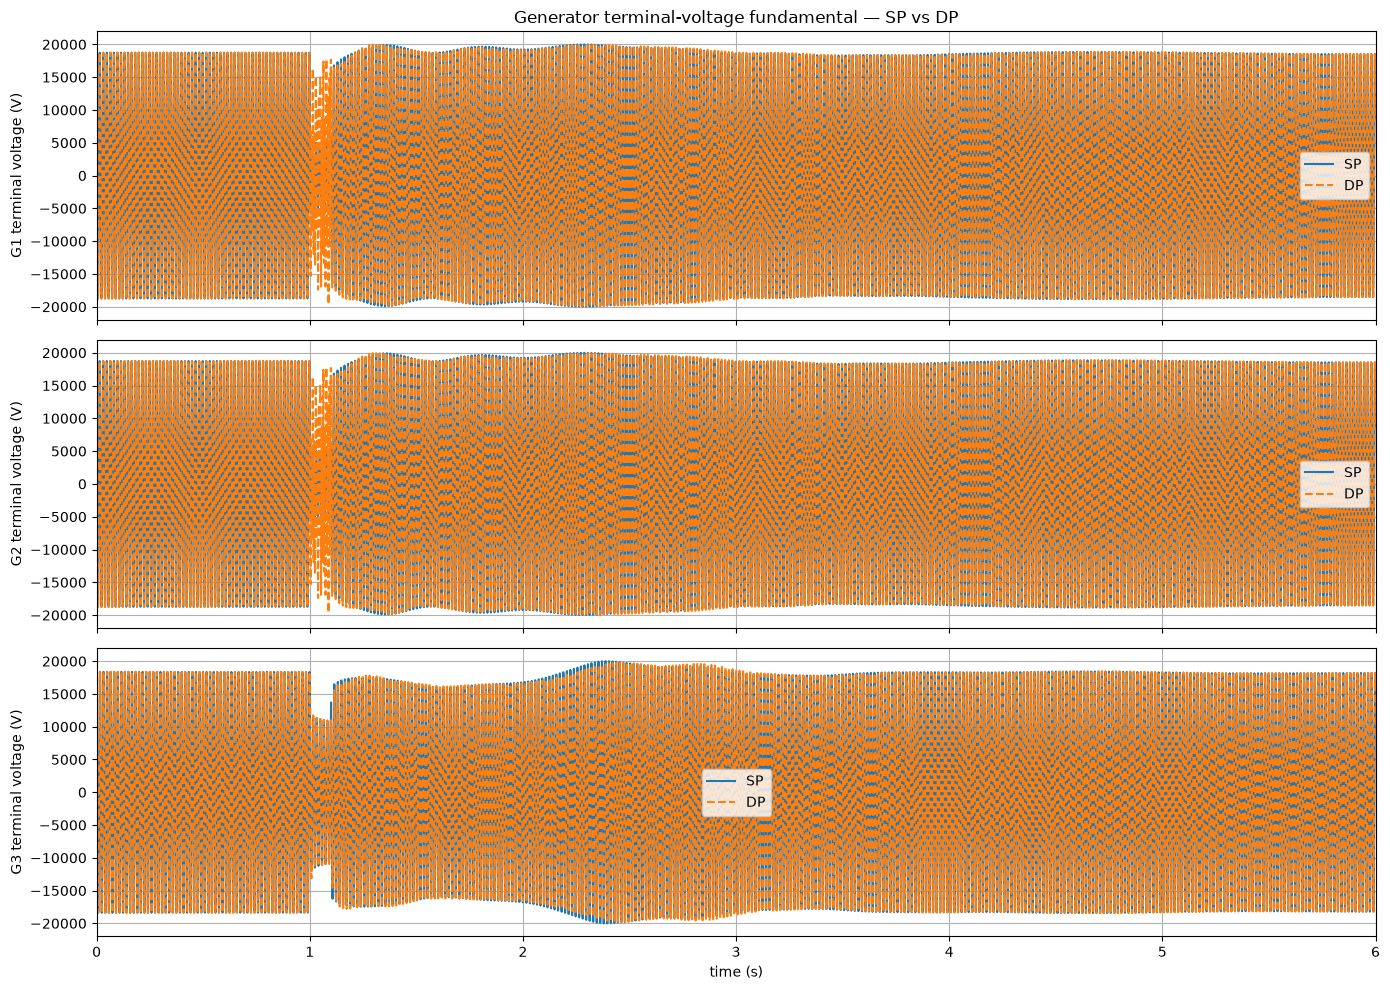

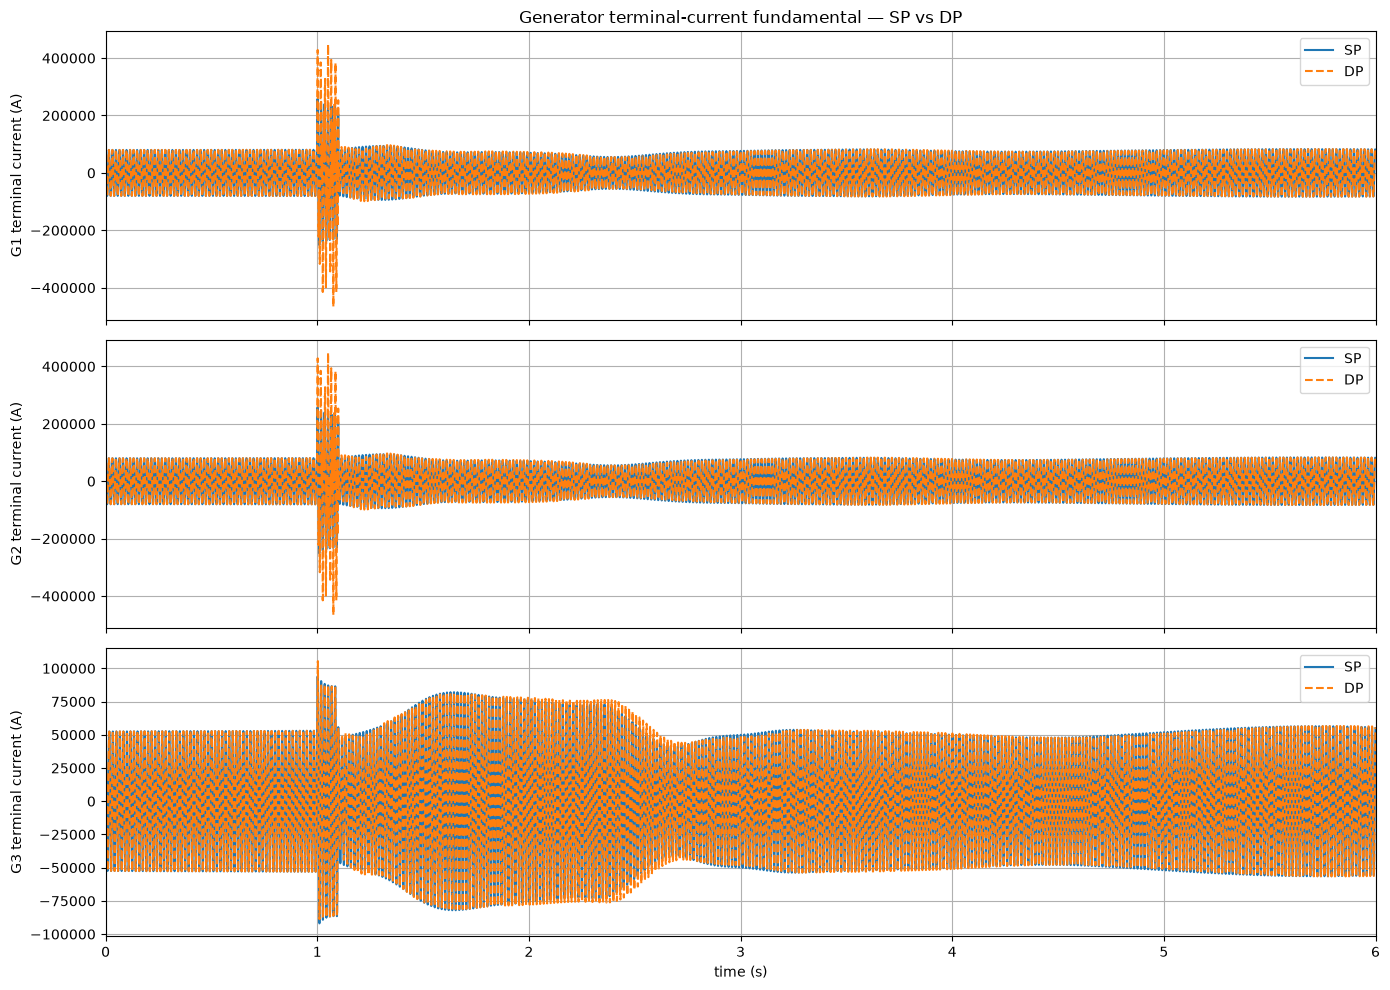

In [14]:
plot_generator_backshift(
    "v_gen", "terminal voltage (V)",
    "Generator terminal-voltage fundamental — SP vs DP"
)
plot_generator_backshift(
    "i_gen", "terminal current (A)",
    "Generator terminal-current fundamental — SP vs DP"
)

# Generator 1,2 and 3 Terminal Voltages #

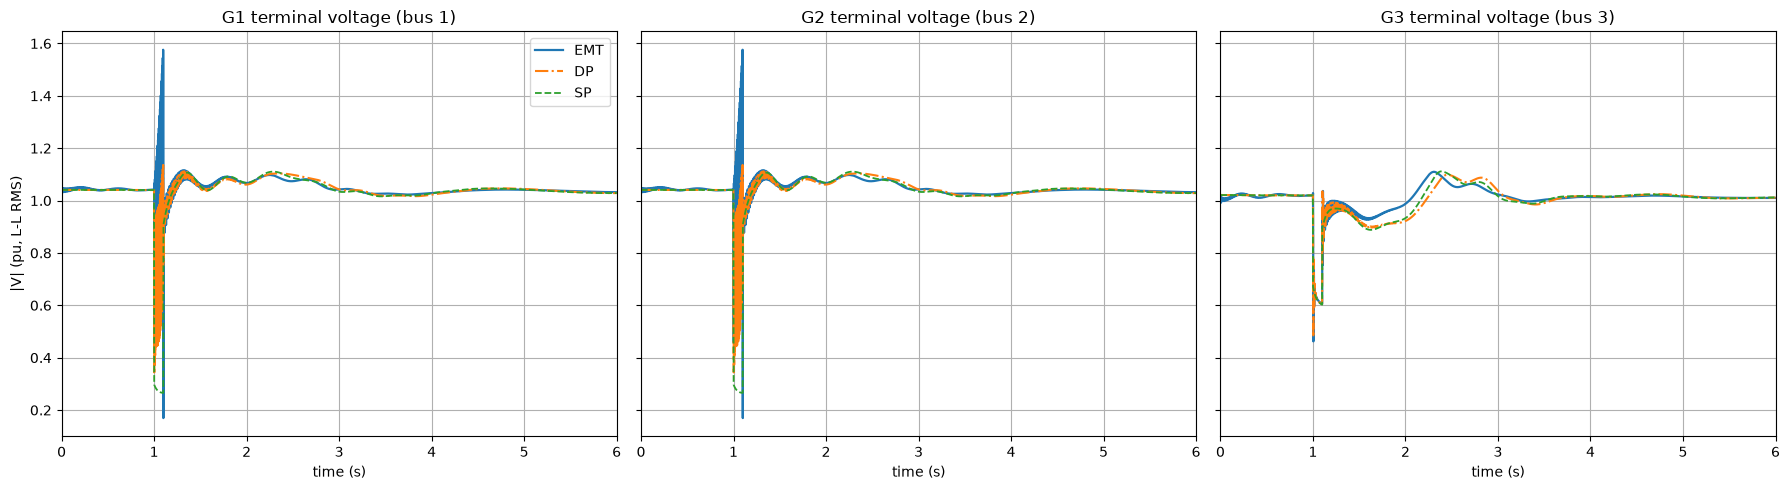

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)
for ax, b in zip(axes, (1, 2, 3)):
    for tag, d, st in DOMS:
        t, v = v_pu(d, tag, b)
        ax.plot(t, v, label=tag, **st)
    ax.set_xlim(0, PLOT_TMAX)
    ax.set_xlabel("time (s)")
    ax.set_title(f"G{b} terminal voltage (bus {b})")
    ax.grid(True)
axes[0].set_ylabel("|V| (pu, L-L RMS)")
axes[0].legend()
fig.tight_layout()
plt.show()


# Generator 1,2 and 3 Rotor Frequencies #

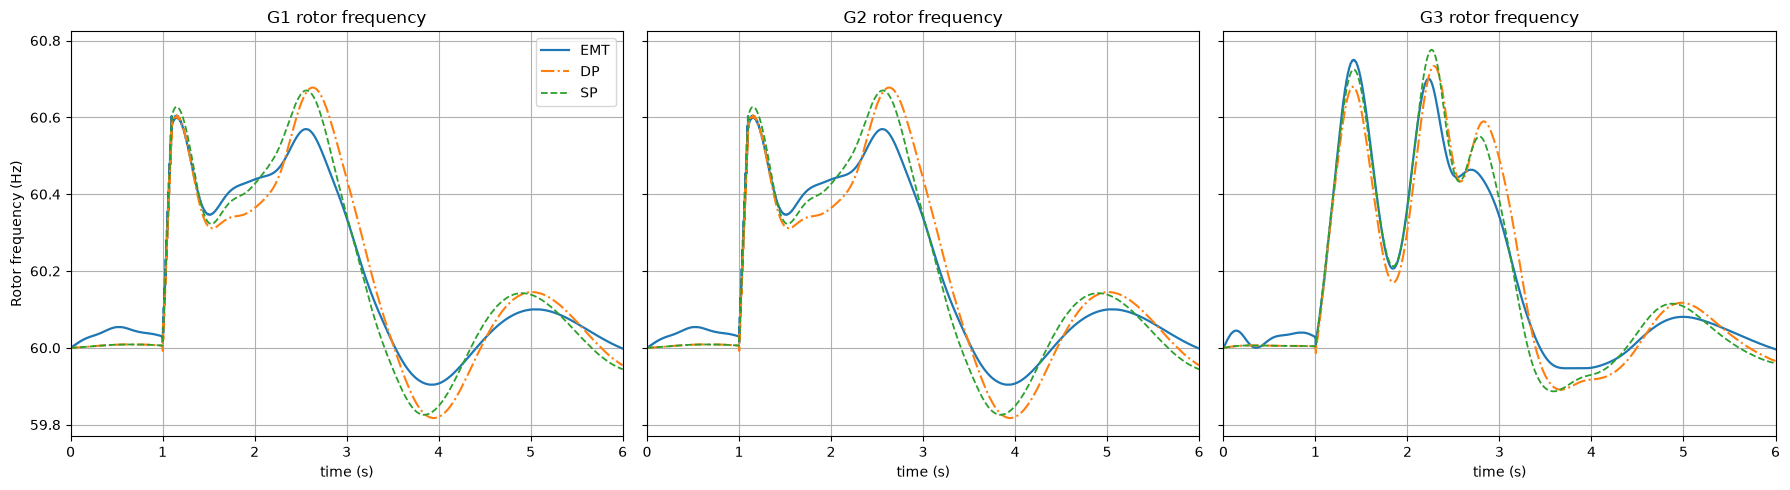

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)
for ax, b in zip(axes, (1, 2, 3)):
    for tag, d, st in DOMS:
        f = np.real(np.asarray(d[f"wr{b}"].values)) * F_NOM
        ax.plot(d[f"wr{b}"].time, f, label=tag, **st)
    ax.set_xlim(0, PLOT_TMAX)
    ax.set_xlabel("time (s)")
    ax.set_title(f"G{b} rotor frequency")
    ax.grid(True)
axes[0].set_ylabel("Rotor frequency (Hz)")
axes[0].legend()
fig.tight_layout()
plt.show()


# Generator 1, 2 & 3 Rotor Angle $\delta$ (SP vs DP) #

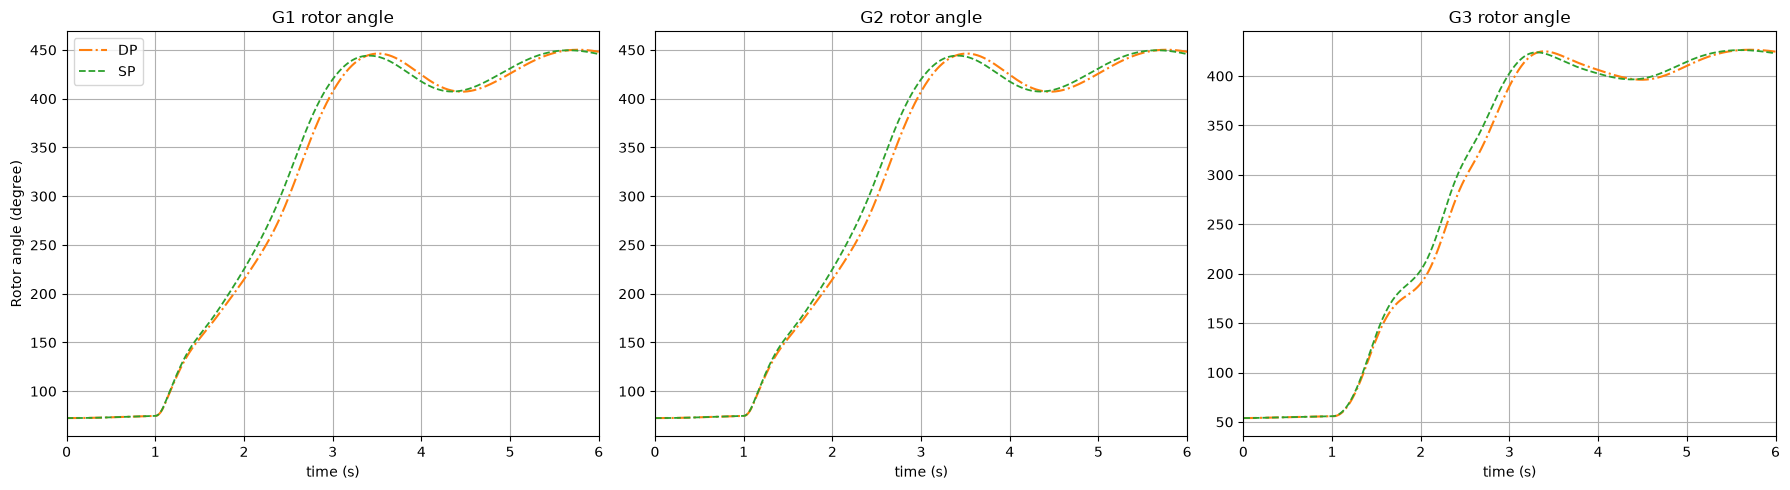

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, b in zip(axes, (1, 2, 3)):
    for tag, d, st in DOMS:
        if tag == "EMT":
            continue
        ax.plot(d[f"dl{b}"].time, np.degrees(np.real(np.array(d[f"dl{b}"].values))), label=tag, **st)
    ax.set_xlim(0, PLOT_TMAX)
    ax.set_xlabel("time (s)")
    ax.set_title(f"G{b} rotor angle")
    ax.grid(True)
axes[0].set_ylabel("Rotor angle (degree)")
axes[0].legend()
fig.tight_layout()
plt.show()

# Generator 1, 2 & 3 Electrical Torque $T_e$ #

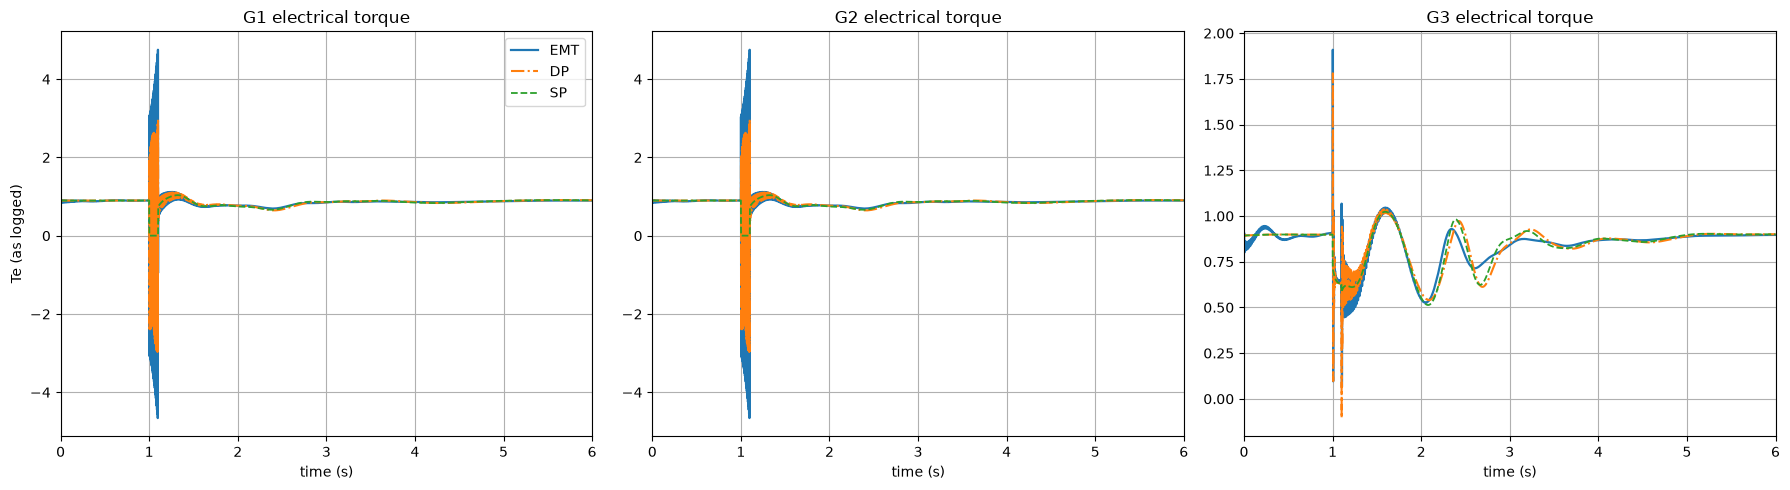

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, b in zip(axes, (1, 2, 3)):
    for tag, d, st in DOMS:
        y = np.real(np.asarray(d[f"Te{b}"].values))
        ax.plot(d[f"Te{b}"].time, y, label=tag, **st)
    ax.set_xlim(0, PLOT_TMAX)
    ax.set_xlabel("time (s)")
    ax.set_title(f"G{b} electrical torque")
    ax.grid(True)
axes[0].set_ylabel("Te (as logged)")
axes[0].legend()
fig.tight_layout()
plt.show()


# Bus 5 Voltage Waveform and Bus 4 Fault Current #

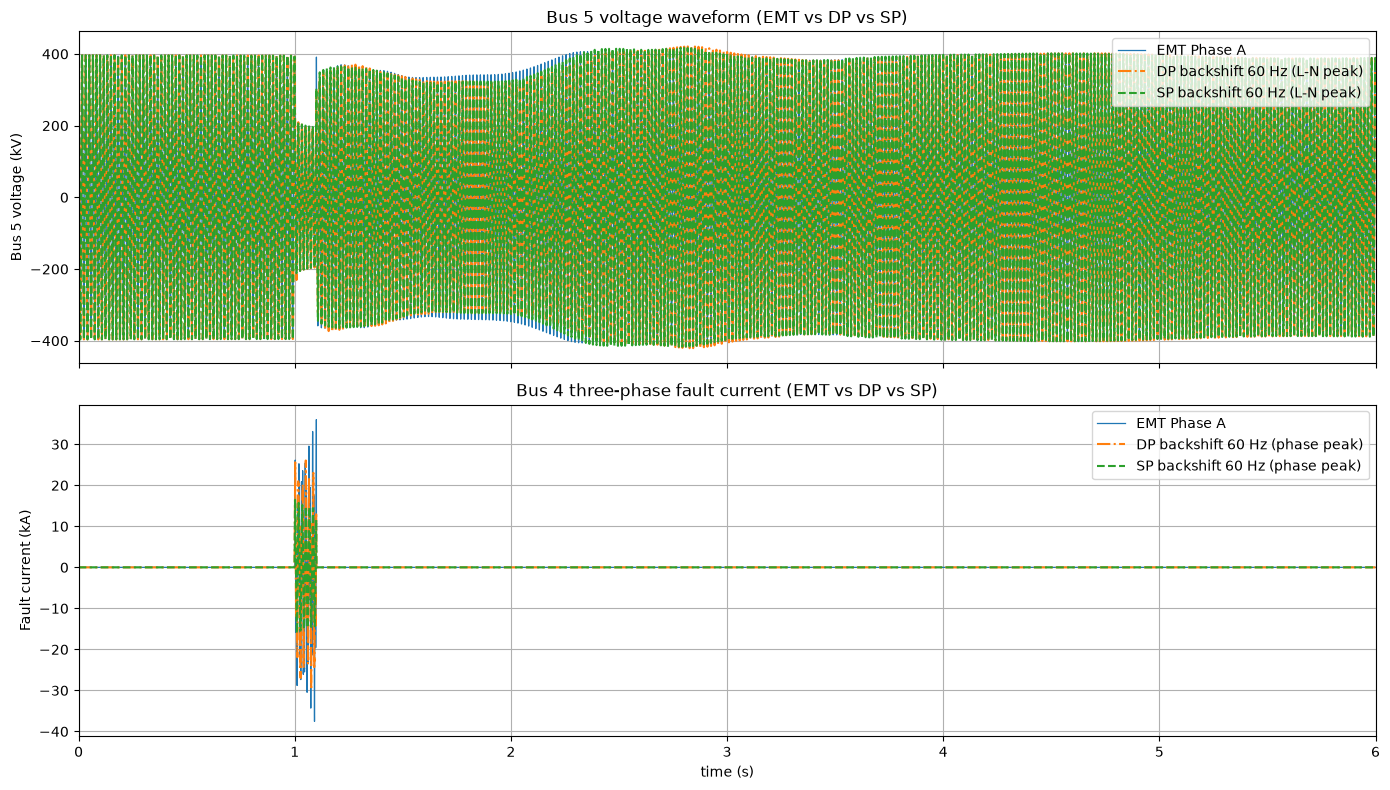

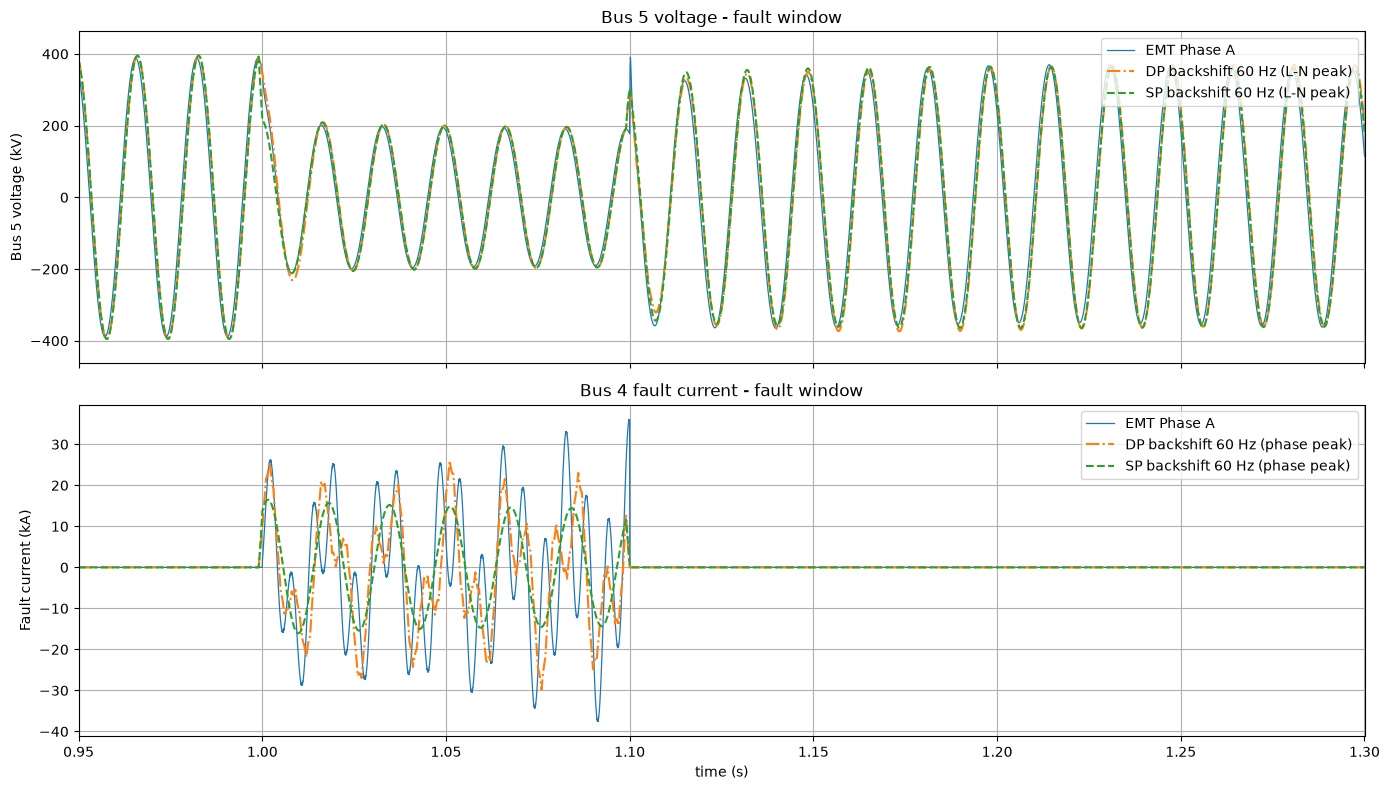

In [19]:
scale_ll_rms_to_ln_peak = np.sqrt(2.0 / 3.0)   # voltage: L-L RMS phasor -> L-N peak
# Current: SP/DP "ph1" components use S = V_LL * conj(I_ph1) (three-phase power convention), so I_ph1 = sqrt(3) * I_phase_rms.
# Phase peak = sqrt(2) * I_phase_rms = sqrt(2/3) * I_ph1   (NOT sqrt(2) * I_ph1, which overestimates by sqrt(3))
scale_i_ph1_to_phase_peak = np.sqrt(2.0 / 3.0)
dp_v5_wave     = ts_dp["v_bus5"].interpolate(DT_EMT).frequency_shift(F_NOM)
sp_v5_wave     = ts_sp["v_bus5"].interpolate(DT_EMT).frequency_shift(F_NOM)
dp_ifault_wave = ts_dp["i_fault"].interpolate(DT_EMT).frequency_shift(F_NOM)
sp_ifault_wave = ts_sp["i_fault"].interpolate(DT_EMT).frequency_shift(F_NOM)

def plot_waveforms(axes, xlim):
    axes[0].plot(ts_emt["v_bus5_0"].time, np.real(ts_emt["v_bus5_0"].values) / 1e3, color="tab:blue", lw=0.9, label="EMT Phase A")
    axes[0].plot(dp_v5_wave.time, np.real(dp_v5_wave.values) * scale_ll_rms_to_ln_peak / 1e3, "-.", color="tab:orange", label="DP backshift 60 Hz (L-N peak)")
    axes[0].plot(sp_v5_wave.time, np.real(sp_v5_wave.values) * scale_ll_rms_to_ln_peak / 1e3, "--", color="tab:green", label="SP backshift 60 Hz (L-N peak)")
    axes[0].set_ylabel("Bus 5 voltage (kV)")

    axes[1].plot(ts_emt["i_fault"].time, np.real(ts_emt["i_fault"].values) / 1e3, color="tab:blue", lw=0.9, label="EMT Phase A")
    axes[1].plot(dp_ifault_wave.time, np.real(dp_ifault_wave.values) * scale_i_ph1_to_phase_peak / 1e3, "-.", color="tab:orange", label="DP backshift 60 Hz (phase peak)")
    axes[1].plot(sp_ifault_wave.time, np.real(sp_ifault_wave.values) * scale_i_ph1_to_phase_peak / 1e3, "--", color="tab:green", label="SP backshift 60 Hz (phase peak)")
    axes[1].set_ylabel("Fault current (kA)")
    axes[1].set_xlabel("time (s)")
    for a in axes:
        a.grid(True)
        a.legend(loc="upper right")
        a.set_xlim(*xlim)

# Full window
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
plot_waveforms(axes, (0, PLOT_TMAX))
axes[0].set_title("Bus 5 voltage waveform (EMT vs DP vs SP)")
axes[1].set_title("Bus 4 three-phase fault current (EMT vs DP vs SP)")
fig.tight_layout()
plt.show()

# Zoom on the fault
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
plot_waveforms(axes, ZOOM)
axes[0].set_title("Bus 5 voltage - fault window")
axes[1].set_title("Bus 4 fault current - fault window")
fig.tight_layout()
plt.show()

# Fault-Current Interpretation #
The single-frequency SP/DP backshift is a reconstructed fundamental-frequency waveform.
It does **not** reproduce the EMT's decaying DC offset. Therefore a raw EMT instantaneous
peak is not directly comparable with the SP/DP reconstructed peak.

For a fair check, this cell estimates the 60 Hz fundamental peak of the EMT phase-A signal
with a sliding one-cycle least-squares fit (including a constant term to remove DC), then
compares that fundamental with the SP and DP reconstructed peaks.

In [20]:
t0, t1 = T_FAULT_ON + 0.03, T_FAULT_OFF


def first_channel(values):
    """Return the real part of the first logged channel as a 1-D array."""
    y = np.real(np.asarray(values))
    if y.ndim > 1:
        y = y.reshape(y.shape[0], -1)[:, 0]
    return np.asarray(y, dtype=float)


def reconstructed_peak(wave, scale=1.0, t0=t0, t1=t1):
    """Maximum absolute value in the selected window, after applying scale."""
    t = np.asarray(wave.time, dtype=float)
    y = first_channel(wave.values) * scale
    mask = (t >= t0) & (t <= t1) & np.isfinite(t) & np.isfinite(y)
    if not mask.any():
        return np.nan
    return float(np.max(np.abs(y[mask])))


def emt_fundamental_peak(time, signal, f0=F_NOM, window_cycles=1.0, t0=t0, t1=t1):
    """Sliding LS estimate of the f0 peak; a constant term absorbs local DC."""
    time = np.asarray(time, dtype=float)
    signal = first_channel(signal)
    good = np.isfinite(time) & np.isfinite(signal)
    time, signal = time[good], signal[good]
    if len(time) < 10:
        return np.nan

    # Restrict the fit to the fault window plus half a fitting window on each side.
    half_window_s = 0.5 * window_cycles / f0
    roi = (time >= t0 - half_window_s) & (time <= t1 + half_window_s)
    time, signal = time[roi], signal[roi]
    if len(time) < 10:
        return np.nan

    dt = float(np.median(np.diff(time)))
    if not np.isfinite(dt) or dt <= 0:
        return np.nan

    # Odd number of samples gives a window symmetric around each center sample.
    half = max(5, int(round(window_cycles / f0 / dt)) // 2)
    if len(time) < 2 * half + 1:
        return np.nan

    omega = 2.0 * np.pi * f0
    stride = max(1, (2 * half + 1) // 20)
    peaks, centers = [], []

    for center_idx in range(half, len(time) - half, stride):
        center_t = time[center_idx]
        if center_t < t0 or center_t > t1:
            continue
        lo, hi = center_idx - half, center_idx + half + 1
        tau = time[lo:hi] - center_t
        yw = signal[lo:hi]
        A = np.column_stack((
            np.cos(omega * tau),
            np.sin(omega * tau),
            np.ones_like(tau),
        ))
        coeff, *_ = np.linalg.lstsq(A, yw, rcond=None)
        peaks.append(float(np.hypot(coeff[0], coeff[1])))
        centers.append(center_t)

    return float(np.max(peaks)) if peaks else np.nan


# DPsim Ph1 current uses the three-phase-equivalent convention. Convert to
# phase-A peak: I_phase,peak = sqrt(2/3) * I_Ph1.
# This scale is defined in the preceding waveform-comparison cell.

sp_t = np.asarray(sp_ifault_wave.time, dtype=float)
sp_y = first_channel(sp_ifault_wave.values) * scale_i_ph1_to_phase_peak

dp_t = np.asarray(dp_ifault_wave.time, dtype=float)
dp_y = first_channel(dp_ifault_wave.values) * scale_i_ph1_to_phase_peak

t_e = np.asarray(ts_emt["i_fault"].time, dtype=float)
i_e = first_channel(ts_emt["i_fault"].values)

# Apply exactly the same 60 Hz estimator to SP, DP, and EMT.
sp_fund_peak = emt_fundamental_peak(sp_t, sp_y)
dp_fund_peak = emt_fundamental_peak(dp_t, dp_y)
emt_fund_peak = emt_fundamental_peak(t_e, i_e)

# Raw peaks retain any additional content in the reconstructed/instantaneous signals.
sp_raw_peak = reconstructed_peak(sp_ifault_wave, scale_i_ph1_to_phase_peak)
dp_raw_peak = reconstructed_peak(dp_ifault_wave, scale_i_ph1_to_phase_peak)
emt_instant_peak = reconstructed_peak(ts_emt["i_fault"], 1.0)

print(
    "60 Hz fundamental phase-A peak : "
    f"SP {sp_fund_peak/1e3:6.2f} | "
    f"DP {dp_fund_peak/1e3:6.2f} | "
    f"EMT {emt_fund_peak/1e3:6.2f} kA"
)
print(
    "Raw peak (reconstructed / instantaneous): "
    f"SP {sp_raw_peak/1e3:6.2f} | "
    f"DP {dp_raw_peak/1e3:6.2f} | "
    f"EMT {emt_instant_peak/1e3:6.2f} kA"
)
print(f"DP / SP fundamental peak ratio  : {dp_fund_peak/sp_fund_peak:.3f}")
print(f"DP / EMT fundamental peak ratio : {dp_fund_peak/emt_fund_peak:.3f}")


60 Hz fundamental phase-A peak : SP  15.31 | DP  18.07 | EMT  16.33 kA
Raw peak (reconstructed / instantaneous): SP  15.21 | DP  29.83 | EMT  37.55 kA
DP / SP fundamental peak ratio  : 1.180
DP / EMT fundamental peak ratio : 1.106
